## Geoginah Ramatshe_26303686

# 5. Results Visualisation

This notebook visualises the target class distribution, class proportions over snapshot dates, model metrics from training/validation and unseen test data, confusion matrices, ROC curves and precision–recall curves. It uses saved CSV outputs from the earlier notebooks.

## Why these visualisations are appropriate

- **Class distribution and target trend:** show class imbalance and whether dormancy rates vary across snapshot dates.
- **Metric comparison:** summarises precision, recall, F1, ROC-AUC and PR-AUC across data splits.
- **Confusion matrix:** shows correct and incorrect active/dormant classifications at a 0.50 threshold.
- **ROC and precision–recall curves:** assess how the models rank customers over different thresholds; precision–recall is particularly useful for an imbalanced dormant class.

Training and validation metrics are diagnostics from the initial training-stage models. Test metrics come from final models refitted on training plus validation data.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Raw CSV files are expected to be in the same folder as these notebooks.
BASE_DIR = Path.cwd()
RAW_FILES = {
    "profile": "table1_customer_profile.csv",
    "funding": "table2_account_funding.csv",
    "transactions": "table3_transaction_trading.csv",
    "engagement": "table4_platform_engagement.csv",}

def safe_date(series):
    return pd.to_datetime(series, errors="coerce")

missing_files = [name for name in RAW_FILES.values() if not (BASE_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        "Could not find these CSV files in the notebook's current folder: "
        + ", ".join(missing_files)
        + ". Place the CSV files beside the notebooks or update BASE_DIR.")

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

PROCESSED_DIR = BASE_DIR / "processed"
RESULTS_DIR = BASE_DIR / "results"

needed = [
    PROCESSED_DIR / "dormancy_snapshot_dataset.csv",
    RESULTS_DIR / "training_validation_metrics.csv",
    RESULTS_DIR / "test_metrics.csv",
    RESULTS_DIR / "test_predictions.csv",
]
missing = [str(p) for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Required outputs are missing. Run notebooks 02, 03 and 04 in order. Missing: "
        + ", ".join(missing))

model_data = pd.read_csv(PROCESSED_DIR / "dormancy_snapshot_dataset.csv", parse_dates=["snapshot_date"])
train_val_metrics = pd.read_csv(RESULTS_DIR / "training_validation_metrics.csv")
test_metrics = pd.read_csv(RESULTS_DIR / "test_metrics.csv")
test_predictions = pd.read_csv(RESULTS_DIR / "test_predictions.csv", parse_dates=["snapshot_date"])

## 1. Class distribution

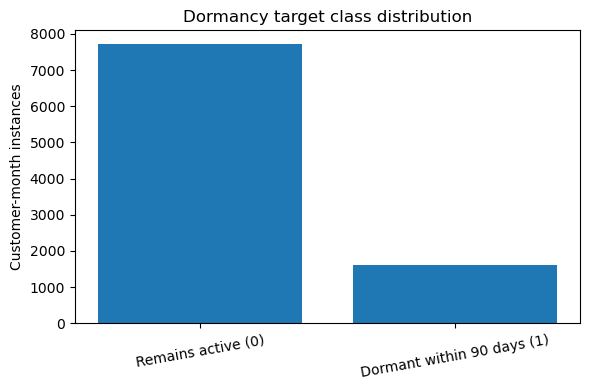

Total customer-month instances: 9,334
Dormant proportion: 17.4%
Active:dormant ratio: 4.76:1


In [2]:
target_counts = model_data["dormancy_target"].value_counts().reindex([0, 1], fill_value=0)
class_labels = ["Remains active (0)", "Dormant within 90 days (1)"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_labels, [target_counts.loc[0], target_counts.loc[1]])
ax.set_title("Dormancy target class distribution")
ax.set_ylabel("Customer-month instances")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
plt.show()

print(f"Total customer-month instances: {len(model_data):,}")
print(f"Dormant proportion: {model_data['dormancy_target'].mean():.1%}")
print(f"Active:dormant ratio: {target_counts.loc[0] / max(target_counts.loc[1], 1):.2f}:1")

## 2. Dormancy proportion over snapshot dates

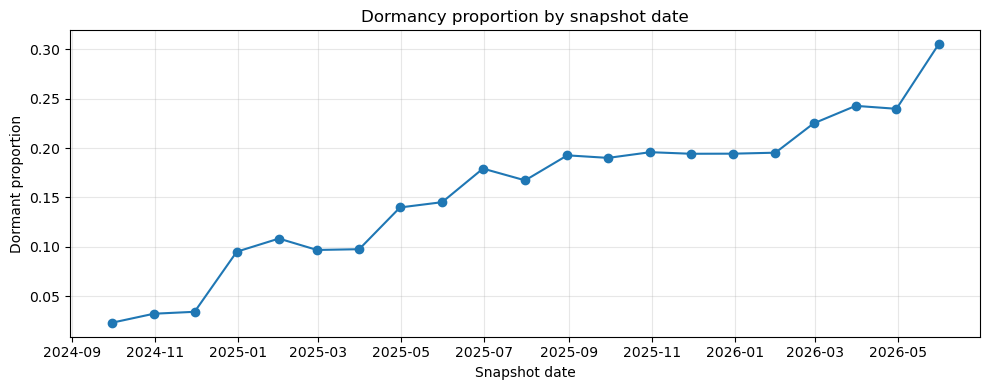

In [3]:
monthly_target = model_data.groupby("snapshot_date")["dormancy_target"].agg(
    instances="size", dormant_proportion="mean").reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_target["snapshot_date"], monthly_target["dormant_proportion"], marker="o")
ax.set_title("Dormancy proportion by snapshot date")
ax.set_xlabel("Snapshot date")
ax.set_ylabel("Dormant proportion")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

this chart checks whether the proportion of dormant records stays stable or changes across snapshot dates.

## 3. Training, validation and test metric comparison

,model,split,instances,dormant_proportion,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,Training,2138,0.0800,0.7306,0.1918,0.7368,0.3043,0.8076,0.2791
1,Logistic Regression,Validation,2553,0.1853,0.5778,0.2810,0.8203,0.4186,0.7607,0.4665
2,XGBoost,Training,2138,0.0800,0.8251,0.2916,0.8304,0.4316,0.9144,0.5270
3,XGBoost,Validation,2553,0.1853,0.6400,0.3126,0.7865,0.4474,0.7596,0.4016
4,Logistic Regression,Test (unseen period),2636,0.2401,0.6324,0.3662,0.7267,0.4870,0.7362,0.5464
5,XGBoost,Test (unseen period),2636,0.2401,0.6525,0.3830,0.7314,0.5027,0.7548,0.6082


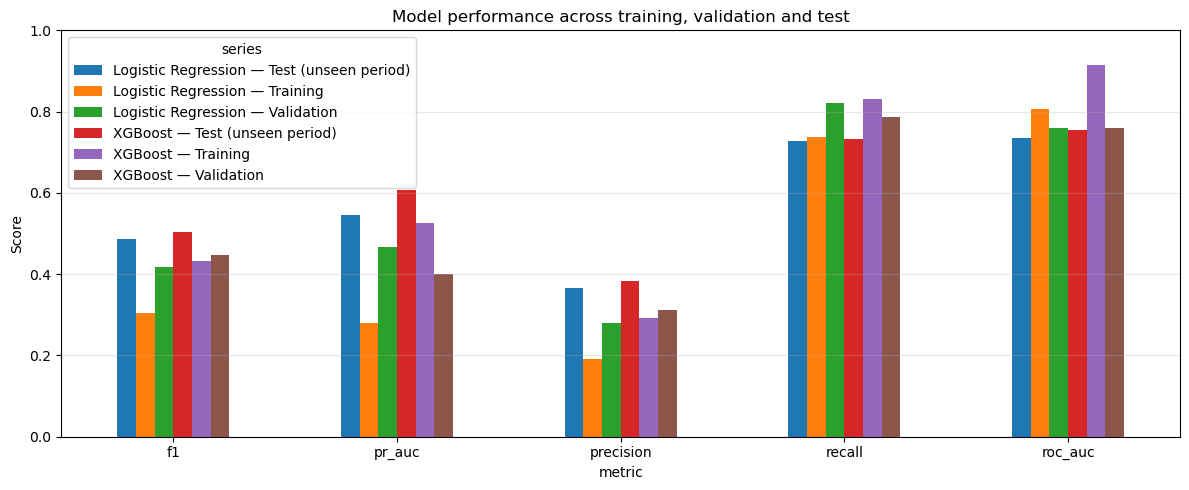

In [4]:
all_metrics = pd.concat([
    train_val_metrics,
    test_metrics.assign(split="Test (unseen period)")
], ignore_index=True, sort=False)

display(all_metrics.round(4))
metrics_to_plot = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
plot_data = all_metrics.melt(id_vars=["model", "split"], value_vars=metrics_to_plot,
                             var_name="metric", value_name="score")

plot_data["series"] = plot_data["model"] + " — " + plot_data["split"]
pivot = plot_data.pivot(index="metric", columns="series", values="score")
ax = pivot.plot(kind="bar", figsize=(12, 5))
ax.set_title("Model performance across training, validation and test")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analysis of the model-metric comparison

On the unseen test period, **XGBoost performed better than Logistic Regression across the reported metrics**:

- Accuracy: **65.3%** for XGBoost versus **63.2%** for Logistic Regression.
- Dormant-class recall: **73.1%** versus **72.7%**.
- Dormant-class precision: **38.3%** versus **36.6%**.
- Dormant-class F1-score: **50.3%** versus **48.7%**.
- ROC-AUC: **0.755** versus **0.736**.
- PR-AUC: **0.608** versus **0.546**.

The strongest relative improvement is in PR-AUC. This suggests XGBoost is better at ranking dormant records ahead of active records across classification thresholds. However, the gains are moderate, and precision remains low: many records flagged as at risk are actually active.

## 4. Confusion matrices on the unseen test period

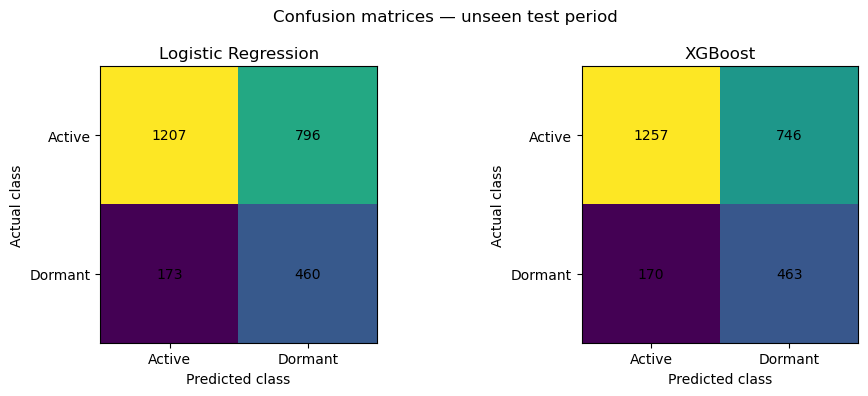

In [5]:
from sklearn.metrics import confusion_matrix

models_to_plot = [("Logistic Regression", "logistic_prediction"),]

if "xgboost_prediction" in test_predictions.columns:
    models_to_plot.append(("XGBoost", "xgboost_prediction"))

fig, axes = plt.subplots(1, len(models_to_plot), figsize=(5 * len(models_to_plot), 4))
if len(models_to_plot) == 1:
    axes = [axes]
for ax, (name, pred_col) in zip(axes, models_to_plot):
    cm = confusion_matrix(test_predictions["actual"], test_predictions[pred_col], labels=[0, 1])
    ax.imshow(cm)
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=["Active", "Dormant"])
    ax.set_yticks([0, 1], labels=["Active", "Dormant"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.suptitle("Confusion matrices — unseen test period")
fig.tight_layout()
plt.show()

### Analysis of the confusion matrices

Read each confusion matrix by comparing the actual class (rows) with the predicted class (columns):

- **Top-left:** active records correctly predicted as active.
- **Top-right:** active records incorrectly flagged as dormant (false positives).
- **Bottom-left:** dormant records incorrectly predicted as active (false negatives).
- **Bottom-right:** dormant records correctly identified (true positives).

For XGBoost, the test matrix contains approximately **463 correctly identified dormant records** and **170 missed dormant records**. It also flags approximately **746 active records as dormant**. This explains the combination of relatively high dormant recall (about 73%) and lower precision (about 38%).

**Business implication:** the model may help STADIOEquities reach many investors who are at risk of becoming dormant, but a retention campaign based on every flagged record could also contact many investors who would have remained active. The best classification threshold should therefore depend on the cost of missing an at-risk investor versus the cost of contacting an active one.

### Key business trade-off from the XGBoost test predictions

The model identifies about 73 out of every 100 dormant records, which is useful if the goal is to contact investors before they disengage. However, of every 100 records flagged as likely to become dormant, only about 38 actually became dormant.

If STADIOEquities uses these predictions for customer-retention campaigns, it could contact many investors who would have remained active anyway. This could increase campaign costs and reduce the efficiency of retention efforts.

## 5. ROC and precision–recall curves

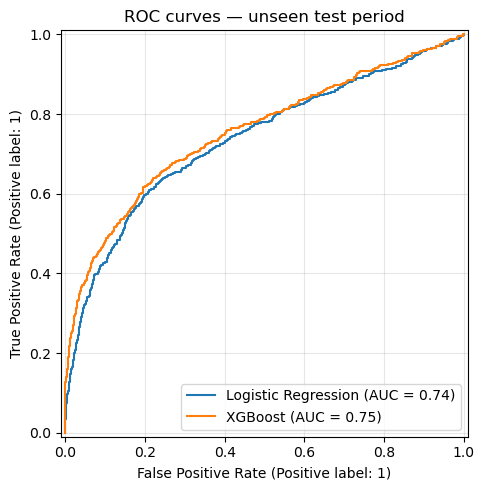

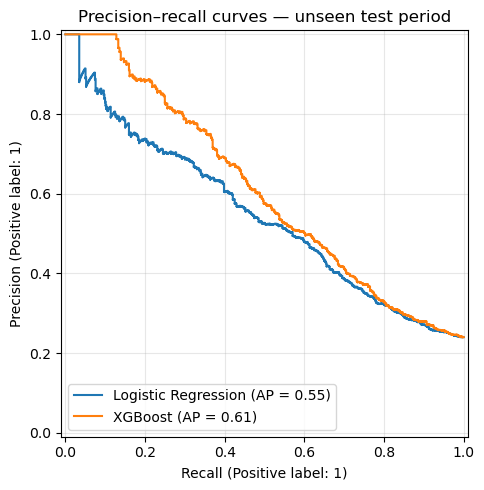

In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

y_true = test_predictions["actual"].astype(int)
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_true, test_predictions["logistic_probability"], name="Logistic Regression", ax=ax)
if "xgboost_probability" in test_predictions.columns:
    RocCurveDisplay.from_predictions(y_true, test_predictions["xgboost_probability"], name="XGBoost", ax=ax)
    
ax.set_title("ROC curves — unseen test period")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions( y_true, test_predictions["logistic_probability"], name="Logistic Regression", ax=ax)

if "xgboost_probability" in test_predictions.columns:
    PrecisionRecallDisplay.from_predictions(y_true, test_predictions["xgboost_probability"], name="XGBoost", ax=ax)
    
ax.set_title("Precision–recall curves — unseen test period")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### Analysis of the ROC and precision–recall curves

**ROC curve:** this shows the trade-off between the true-positive rate and false-positive rate at different thresholds. A curve closer to the top-left corner is generally better, and an ROC-AUC closer to 1 indicates stronger ranking ability. The test ROC-AUC values are **0.755 for XGBoost** and **0.736 for Logistic Regression**, so XGBoost separates the two classes somewhat better overall.

**Precision–recall curve:** this shows how precision changes as recall increases. It is particularly useful here because dormant records are the minority class. XGBoost's test PR-AUC is **0.608**, compared with **0.546** for Logistic Regression, supporting XGBoost as the stronger candidate in this experiment.